# Laboratorium 2B, cz. 1: fine-tuning YOLOv8n na 5 klas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import utils_common as w
import utils_yolo as y

TRAIN = False  # True = trening od nowa (ok. 33 min na RTX 4060 Laptop), False = wczytaj gotowy przebieg
(w.LAB5 / "wykresy").mkdir(exist_ok=True)
manifest = w.make_manifest()
print({k: len(v) for k, v in manifest["splits"].items()})

{'train': 1050, 'val': 150, 'test': 300}


## Dane w formacie YOLO
Etykiety powstaja w lab5, zdjecia to hardlinki do lab4 (bez kopii). Klasy: znak + swiatlo w 4 kolorach.

In [2]:
y.convert()
for split in ("train", "val", "test"):
    labels = [l.split()[0] for f in (y.DATA / "labels" / split).glob("*.txt") for l in f.read_text().splitlines() if l]
    print(split, pd.Series(labels).map(lambda i: y.NAMES[int(i)]).value_counts().to_dict())

train {'traffic_sign': 3588, 'traffic_light_green': 1133, 'traffic_light_unknown': 983, 'traffic_light_red': 698, 'traffic_light_yellow': 50}
val {'traffic_sign': 474, 'traffic_light_green': 170, 'traffic_light_red': 122, 'traffic_light_unknown': 113, 'traffic_light_yellow': 8}
test {'traffic_sign': 977, 'traffic_light_green': 348, 'traffic_light_unknown': 243, 'traffic_light_red': 179, 'traffic_light_yellow': 14}


## Trening

In [3]:
if TRAIN:
    y.train()
args = dict(l.split(": ", 1) for l in (y.RUN / "args.yaml").read_text().splitlines() if ": " in l)
print({k: args[k] for k in ("model", "epochs", "patience", "batch", "imgsz", "seed", "optimizer", "lr0", "device")})

{'model': 'C:\\Users\\hubi_\\Desktop\\Dane\\Studia\\AGH\\III sem\\Rozpoznawanie wzorcĂłw\\lab5\\yolov8n.pt', 'epochs': '60', 'patience': '15', 'batch': '8', 'imgsz': '1280', 'seed': '42', 'optimizer': 'auto', 'lr0': '0.01', 'device': '"0"'}


## Krzywe uczenia (walidacja)

epok: 55 | najlepsza epoka (val): 40 | mAP50: 0.48 | mAP50-95: 0.198 | P: 0.608 | R: 0.488


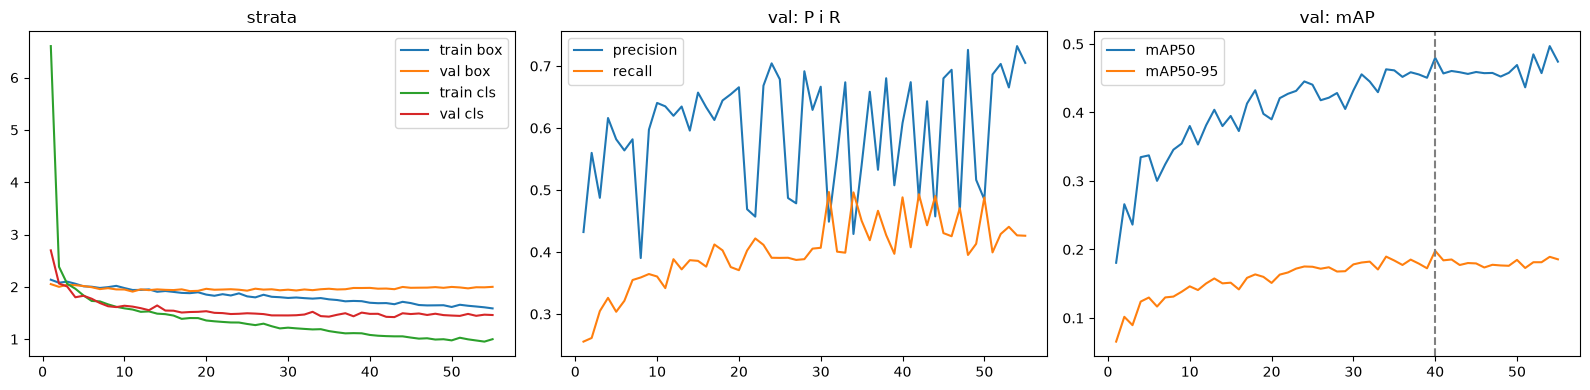

In [4]:
res = pd.read_csv(y.RUN / "results.csv")
res.columns = [c.strip() for c in res.columns]
res["fitness"] = .1 * res["metrics/mAP50(B)"] + .9 * res["metrics/mAP50-95(B)"]
best = res.loc[res["fitness"].idxmax()]
print("epok:", len(res), "| najlepsza epoka (val):", int(best["epoch"]),
      "| mAP50:", round(best["metrics/mAP50(B)"], 3), "| mAP50-95:", round(best["metrics/mAP50-95(B)"], 3),
      "| P:", round(best["metrics/precision(B)"], 3), "| R:", round(best["metrics/recall(B)"], 3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for col, name in (("train/box_loss", "train box"), ("val/box_loss", "val box"), ("train/cls_loss", "train cls"), ("val/cls_loss", "val cls")):
    ax[0].plot(res["epoch"], res[col], label=name)
ax[0].set_title("strata"); ax[0].legend()
ax[1].plot(res["epoch"], res["metrics/precision(B)"], label="precision"); ax[1].plot(res["epoch"], res["metrics/recall(B)"], label="recall")
ax[1].set_title("val: P i R"); ax[1].legend()
ax[2].plot(res["epoch"], res["metrics/mAP50(B)"], label="mAP50"); ax[2].plot(res["epoch"], res["metrics/mAP50-95(B)"], label="mAP50-95")
ax[2].axvline(best["epoch"], color="gray", linestyle="--"); ax[2].set_title("val: mAP"); ax[2].legend()
fig.tight_layout(); fig.savefig(w.LAB5 / "wykresy" / "trening_krzywe.png", dpi=100)

To jest mAP z ultralytics na val. Nasza metryka (F1 przy IoU 0,5) jest w drugim notebooku, na tescie.